In [40]:
import pandas as pd               #Libraries Import
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df = pd.read_csv("cleaned_orders_updated1.csv")  #read data

In [42]:
df.head() #dataset check

,Unnamed: 0,order_id,customer_name,age,gender,email,state,order_date,ship_date,category,product,quantity,unit_price,payment_method,order_status,rating
0,0,ORD1205,Suresh Smith,49,Male,suresh.smith77@gmail.com,Kerala,24-05-2025,02-06-2025,BEAUTY,Face Wash,3,2490.0,NET BANKING,delivered,3
1,1,ORD1302,Arjun Iyer,28,Male,arjun.iyer22@yahoo.com,Kerala,05-01-2024,12-01-2024,CLOTHING,t-shirt,1,5990.0,CASH ON DELIVERY,delivered,4
2,2,ORD1234,meera khan,62,Male,meera.khan96@yahoo.com,Maharashtra,10-12-2024,14-12-2024,HOME & KITCHEN,Dinner Set,1,21990.0,UPI,pending,1
3,3,ORD1231,SURESH SHARMA,30,Female,suresh.sharma81@gmail.com,Tamil Nadu,18-03-2025,27-03-2025,BEAUTY,Hair Serum,2,6990.0,NET BANKING,delivered,4
4,4,ORD1260,Karthik Sharma,47,Male,karthik.sharma6@outlook.com,Tamil Nadu,23-08-2025,27-08-2025,BOOKS,SQL Guide,1,5990.0,NET BANKING,shipped,5


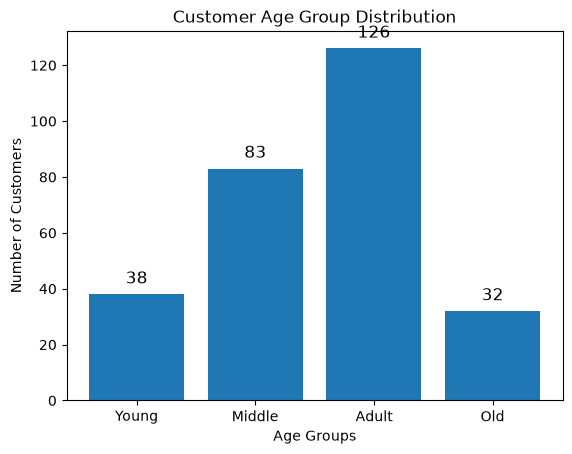

In [43]:
# Customer Age Group - Bar Chart

df = df[df["age"].between(18, 100)].copy()

df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 40, 60, 100],
    labels=["Young", "Middle", "Adult", "Old"]
)

age_count = df["age_group"].value_counts().reindex(
    ["Young", "Middle", "Adult", "Old"]
)

bars = plt.bar(age_count.index, age_count.values)

plt.bar_label(bars, fmt="%d", padding=5, fontsize=12)

plt.title("Customer Age Group Distribution")
plt.xlabel("Age Groups")
plt.ylabel("Number of Customers")
plt.show()

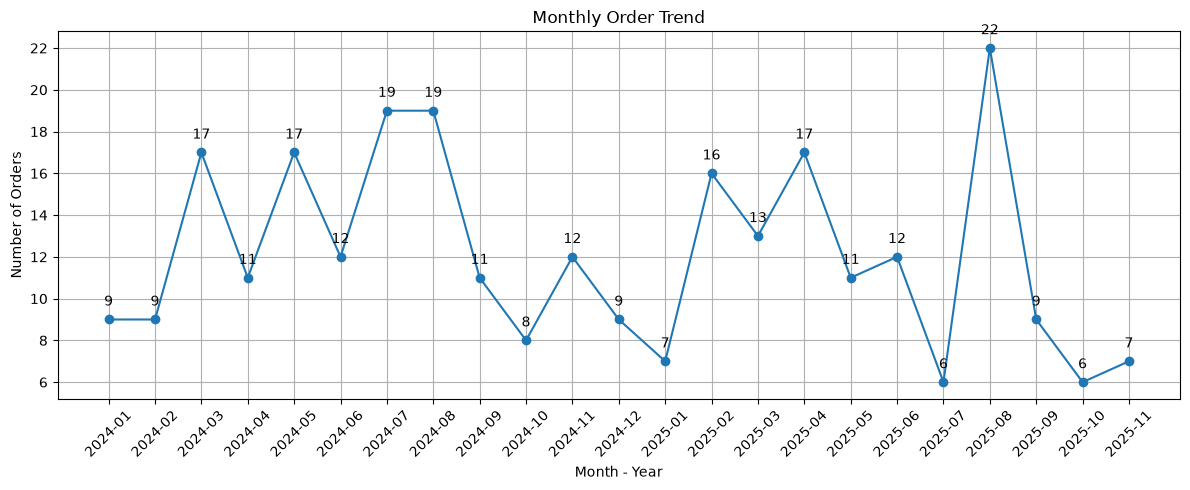

In [44]:
df["order_date"] = pd.to_datetime(df["order_date"], dayfirst=True)

monthly_orders = df.groupby(
    df["order_date"].dt.to_period("M")
)["order_id"].count()

plt.figure(figsize=(12, 5))

plt.plot(monthly_orders.index.astype(str),
         monthly_orders.values, marker="o")

# Display numbers above each point
for i, value in enumerate(monthly_orders.values):
    plt.annotate(
        f"{value:,}",
        (i, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10
    )

plt.title("Monthly Order Trend")
plt.xlabel("Month - Year")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

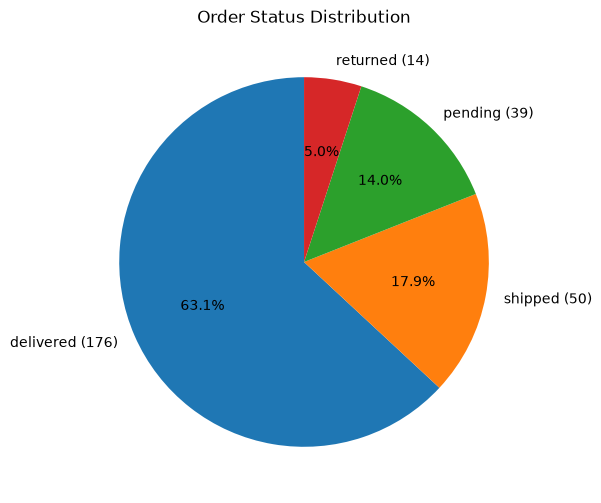

In [45]:
# Count orders by status
status_count = df["order_status"].value_counts()

# Display count along with status name
labels = [f"{status} ({count})"
          for status, count in status_count.items()]

plt.figure(figsize=(8, 6))

plt.pie(
    status_count.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Status Distribution")
plt.show()

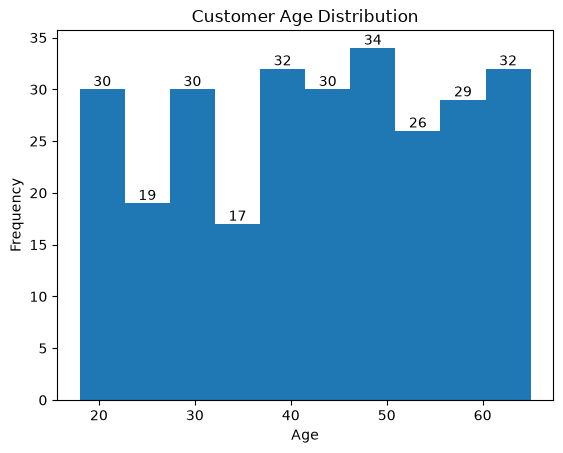

In [46]:
# Customer Age Distribution - Histogram
age_data = df[df["age"].between(18, 100)]
counts, bins, patches = plt.hist(age_data["age"], bins=10)

# Display numbers above bars
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            int(count),
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

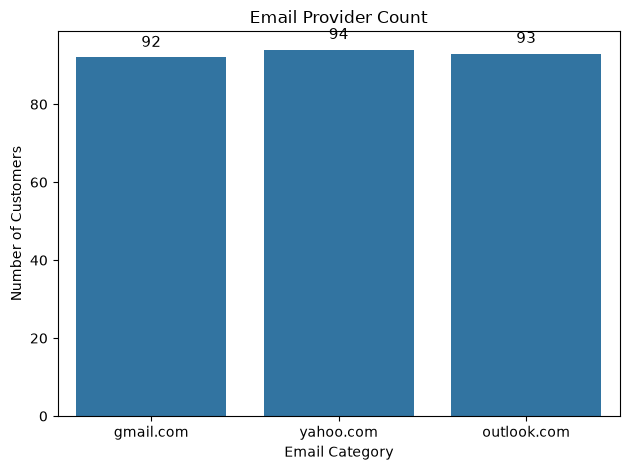

In [47]:
# Email Provider Count

df["email_category"] = df["email"].str.split("@").str[-1]

ax = sns.countplot(data=df, x="email_category")

# Display numbers above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5, fontsize=11)

plt.title("Email Provider Count")
plt.xlabel("Email Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()